# 08. xLSTM — 용담댐 시간 유입량 예측 (입력세트 A / B / C)

**모델**: xLSTM (`model: x_lstm`) — 순환(확장 LSTM)
**한 줄 요약**: 확장 LSTM. 지수 게이트와 행렬 메모리(mLSTM)·스칼라 메모리(sLSTM) 블록을 쌓아 LSTM의 저장 용량과 병렬성을 개선.

이 노트북은 모델 비교 연구(10개 모델 × 3개 입력세트)의 **xLSTM 부분**입니다. 모든 모델 노트북이 같은 구성을 가집니다.

1. 모델 설명 (논문 methodology용)
2. 자료와 실험 설정
3. 학습 (입력세트 A, B, C) 과 학습곡선
4. 학습 / 검증 / 테스트 기간 성능
5. 수문곡선 · 산점도 · 유량지속곡선
6. 홍수 첨두 재현
7. 결과 해석
8. 요약 (비교 노트북 `11_Comparison_Overall.ipynb`, `12_Comparison_Peaks.ipynb` 에서 사용하는 `results/xlstm_<set>/` 생성)

**연구 설정 요약**

| 항목 | 내용 |
|---|---|
| 대상 | 용담댐 (유역면적 930.42 km²) 시간 유입량 (m³/s) |
| 기간 | 2006-01-01 ~ 2025-12-31 (20년, 175,320 시간) |
| 학습 / 검증 / 테스트 | 2006–2017 (12년) / 2018–2021 (4년) / 2022–2025 (4년) |
| 입력세트 A | 유역평균 강수량 `rf_avg` (1변수) |
| 입력세트 B | 관측소별 강수량 `rf_<관측소>` × 7 (7변수) |
| 입력세트 C | A + B (8변수) |
| 해상도 | 시간(hourly). MTS-LSTM만 일(daily) 강우를 추가로 사용 |
| 공통 학습 설정 | Adam, lr 1e-3, batch 256, MSE, seq_length 720 h, epoch 30–50 (early stopping patience 5), seed 111 |
| 평가 epoch | 검증 loss가 최소인 epoch (early stopping은 학습을 멈출 뿐 가중치를 되돌리지 않음) |
| 데이터셋 클래스 | `hourlycsv` (`data/YDDam_paper/`) — `prepare_data.py` 로 생성 |
| 설정 파일 | `configs/<model>_<set>.yml` — `make_configs.py` 로 생성 |
| 공통 코드 | `common.py` (run 관리·평가·그림), `model_docs.py` (모델 설명) |



## 1. 모델 설명 (Methodology)

**xLSTM (Extended LSTM; Beck et al., 2024; NeuralHydrology `x_lstm`)**

LSTM의 두 가지 한계(저장 용량, 게이트의 시그모이드 포화)를 고친 두 종류의 블록을 쌓은 모델이다.

- **mLSTM 블록**: 셀 상태를 벡터가 아닌 **행렬 $C_t \in \mathbb{R}^{d\times d}$** 로 두고, 키·값 쌍을 외적으로 저장한다.
  $C_t = f_t C_{t-1} + i_t\, v_t k_t^\top$, $h_t = o_t \odot \frac{C_t q_t}{\max(|n_t^\top q_t|, 1)}$.
  시간 단계 간 은닉 상태 의존이 없어 **완전 병렬** 학습이 가능하다(주의 메커니즘과 유사한 연상 기억).
- **sLSTM 블록**: 기존 LSTM에 **지수 게이트** $i_t = \exp(\cdot)$ 와 정규화 상태 $n_t$ 를 도입해 "저장 결정을 나중에 번복"할 수 있게 하고,
  다중 헤드로 메모리를 섞는다. 순환 의존이 남아 있어 CUDA 커널로 구현된다.

본 연구는 2개 블록(`xlstm_num_blocks: 2`, 두 번째가 sLSTM)을 4개 헤드로 쓴다. 입력은 선형 변환으로 64차원에 맞춘다.

### 1.1 수문학적 관점에서의 특징

- 행렬 메모리는 **여러 강우 사상을 서로 다른 키로 동시에 저장**할 수 있어, 선행 사상이 겹치는 장마철 복합 홍수에서 유리할 수 있다.
- 지수 게이트는 큰 입력(집중호우)에 대해 게이트가 포화되지 않아 **첨두 반응의 크기**를 더 잘 표현할 가능성이 있다.
- 720시간 창에 대한 mLSTM의 병렬 커널은 **GPU 메모리를 크게**(≈ 21 GB) 사용하므로 학습 시 다른 run 과 GPU를 공유하지 않는다.

### 1.2 본 연구에서의 설정

| 항목 | 값 | 이유 |
|---|---|---|
| `hidden_size` | 64 | 동일 |
| `xlstm_num_blocks` / `xlstm_slstm_at` | 2 / [1] | mLSTM → sLSTM 순서 |
| `xlstm_heads` | 4 | 다중 헤드 메모리 |
| `xlstm_kernel_size` / `xlstm_proj_factor` | 4 / 1.3 | 공식 구현 기본값 |

### 참고문헌

- Beck, M., Pöppel, K., Spanring, M., Auer, A., Prudnikova, O., Kopp, M., Klambauer, G., Brandstetter, J., & Hochreiter, S. (2024). xLSTM: Extended long short-term memory. *NeurIPS*.


## 2. 자료와 실험 설정

`common.py` 가 run 디렉터리 탐색, 평가, 그림을 모두 담당하므로 노트북 코드는 짧습니다. 아래 셀은 공통 설정을 불러오고 그림 스타일(큰 글꼴,
300 dpi 저장)을 지정합니다.

In [1]:
%matplotlib inline
import sys, warnings
warnings.filterwarnings("ignore", message=".*IProgress.*")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

sys.path.insert(0, str(Path.cwd()))
import common
from common import SETS, MODEL_NAME, MODEL_COLOR, SET_COLOR, SET_STYLE, PERIODS, PERIOD_LABEL
from model_docs import MODEL_DOCS, MODEL_FAMILY

warnings.filterwarnings("ignore", category=FutureWarning)
common.set_plot_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

MODEL = "xlstm"
NAME = MODEL_NAME[MODEL]
print(NAME, "->", common.MODEL_SPECS[MODEL]["nh_model"])

xLSTM -> x_lstm


### 2.1 자료 개요

연도별 유역평균 강수량과 유입량(평균·최대)입니다. 음영은 학습(회색) / 검증(주황) / 테스트(녹색) 기간입니다.
테스트 기간(2022–2025)에는 2023년과 2024년의 큰 홍수가 포함되어 있고, 학습 기간에는 2020년(최대 4,395 m³/s)이 **포함되지 않는다**는 점에 유의합니다
(2020년은 검증 기간). 즉 모델은 학습에서 본 적 없는 크기의 홍수를 검증·테스트에서 재현해야 하며, 이것이 모델 간 외삽 능력 차이를 드러냅니다.

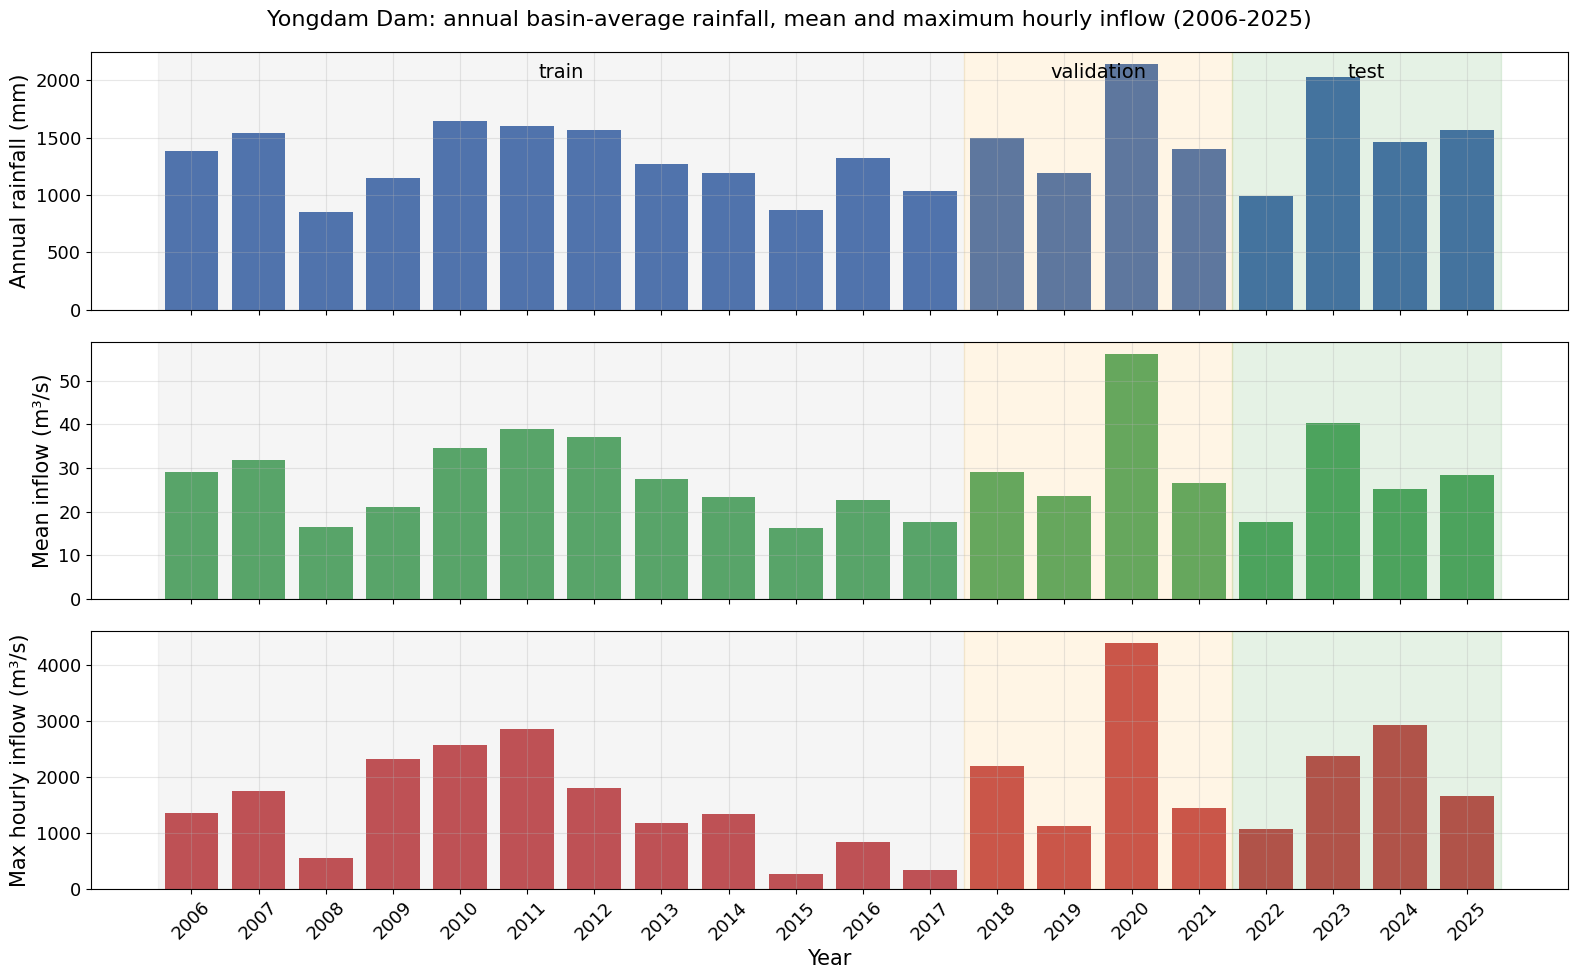

In [2]:
rain = common.load_rainfall(["rf_avg"])["rf_avg"]
inflow = common.load_observed_inflow()
annual = pd.DataFrame({"rain_mm": rain.resample("YE").sum(), "inflow_mean": inflow.resample("YE").mean(),
                       "inflow_max": inflow.resample("YE").max()})
annual.index = annual.index.year
annual = annual.loc[2006:2025]

fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=True)
axes[0].bar(annual.index, annual["rain_mm"], color="#4c72b0")
axes[0].set_ylabel("Annual rainfall (mm)")
axes[1].bar(annual.index, annual["inflow_mean"], color="#55a868")
axes[1].set_ylabel("Mean inflow (m³/s)")
axes[2].bar(annual.index, annual["inflow_max"], color="#c44e52")
axes[2].set_ylabel("Max hourly inflow (m³/s)")
for ax in axes:
    ax.axvspan(2005.5, 2017.5, color="gray", alpha=0.08)
    ax.axvspan(2017.5, 2021.5, color="orange", alpha=0.10)
    ax.axvspan(2021.5, 2025.5, color="green", alpha=0.10)
axes[0].text(2011.5, axes[0].get_ylim()[1] * 0.9, "train", ha="center", fontsize=14)
axes[0].text(2019.5, axes[0].get_ylim()[1] * 0.9, "validation", ha="center", fontsize=14)
axes[0].text(2023.5, axes[0].get_ylim()[1] * 0.9, "test", ha="center", fontsize=14)
axes[2].set_xlabel("Year")
axes[2].set_xticks(annual.index)
axes[2].tick_params(axis="x", rotation=45)
fig.suptitle("Yongdam Dam: annual basin-average rainfall, mean and maximum hourly inflow (2006-2025)", fontsize=16)
fig.tight_layout()
plt.show()


### 2.2 입력세트별 설정 파일

세 입력세트의 설정은 `dynamic_inputs` (와 모델에 따라 그에 연동된 몇 개 키)만 다릅니다. 아래 표는 공통 설정과 다른 항목만 보여 줍니다.
전체 파일은 `configs/xlstm_<set>.yml` 입니다.

In [3]:
rows = {}
for s in SETS:
    rows[f"Set {s}"] = {k: str(v) for k, v in common.model_specific_config(MODEL, s).items()}
cfg_table = pd.DataFrame(rows).fillna("")
display(cfg_table)
print(Path(common.config_path(MODEL, "A")).read_text())

,Set A,Set B,Set C
experiment_name,xlstm_A,xlstm_B,xlstm_C
model,x_lstm,x_lstm,x_lstm
hidden_size,64,64,64
xlstm_num_blocks,2,2,2
xlstm_slstm_at,[1],[1],[1]
xlstm_heads,4,4,4
xlstm_kernel_size,4,4,4
xlstm_proj_factor,1.3,1.3,1.3
output_dropout,0.4,0.4,0.4
dynamic_inputs,['rf_avg'],"['rf_9000028', 'rf_9000027', 'rf_9000023', 'rf...","['rf_avg', 'rf_9000028', 'rf_9000027', 'rf_900..."


experiment_name: xlstm_A
run_dir: null
train_basin_file: YDDam_basin.txt
validation_basin_file: YDDam_basin.txt
test_basin_file: YDDam_basin.txt
train_start_date: 01/01/2006
train_end_date: 31/12/2017
validation_start_date: 01/01/2018
validation_end_date: 31/12/2021
test_start_date: 01/01/2022
test_end_date: 31/12/2025
seed: 111
device: cuda:0
validate_every: 1
validate_n_random_basins: 1
metrics:
- NSE
- KGE
head: regression
output_activation: linear
optimizer: Adam
loss: MSE
learning_rate:
  0: 0.001
batch_size: 256
epochs: 50
clip_gradient_norm: 1
early_stopping: true
patience_early_stopping: 5
minimum_epochs_before_early_stopping: 30
patience_dynamic_learning_rate: 3
factor_dynamic_learning_rate: 0.5
seq_length: 720
predict_last_n: 1
num_workers: 4
log_interval: 100
log_tensorboard: false
log_n_figures: 0
save_weights_every: 1
save_validation_results: false
dataset: hourlycsv
data_dir: ../../data/YDDam_paper
forcings:
- hourly
target_variables:
- inflow
clip_targets_to_zero:
- infl

## 3. 학습

`common.train()` 은 완료된 run (`runs/xlstm_<set>_<날짜>_<시각>/`) 이 있으면 학습을 건너뛰고, 없으면 `nh-run train` 을 서브프로세스로
실행합니다 (`train_all.py` 로 미리 학습해 두어도 같은 run 을 사용합니다). 이어서 `common.evaluate_run()` 이

1. `output.log` 에서 epoch별 학습/검증 loss 와 검증 NSE/KGE 를 읽고,
2. 검증 loss 최소 epoch 을 골라 학습·검증·테스트 기간을 평가(`nh-run evaluate`)하고,
3. 시간 단위 예측을 m³/s 로 통일해 지표를 계산한 뒤 `results/xlstm_<set>/` 에 저장합니다.

In [4]:
summaries, histories, preds = {}, {}, {}
for s in SETS:
    run_dir = common.train(MODEL, s, in_process=False)
    summaries[s] = common.evaluate_run(MODEL, s, run_dir)
    histories[s] = common.load_saved_history(MODEL, s)
    preds[s] = common.load_saved_predictions(MODEL, s)
    print(f"Set {s}: run={summaries[s]['run_dir']}  epochs={summaries[s]['epochs_trained']}  best={summaries[s]['best_epoch']}  "
          f"params={summaries[s]['n_parameters']:,}  {summaries[s]['epoch_time_mean_s']:.0f} s/epoch")

[xlstm_A] completed run found, skipping training: xlstm_A_2110_023138
Set A: run=xlstm_A_2110_023138  epochs=42  best=27  params=63,945  158 s/epoch
[xlstm_B] completed run found, skipping training: xlstm_B_2110_043440
Set B: run=xlstm_B_2110_043440  epochs=41  best=24  params=64,329  155 s/epoch
[xlstm_C] completed run found, skipping training: xlstm_C_2110_063323


Set C: run=xlstm_C_2110_063323  epochs=36  best=29  params=64,393  156 s/epoch


### 3.1 학습곡선

왼쪽: 학습 loss(표준화된 MSE), 가운데: 검증 loss, 오른쪽: 검증 기간(2018–2021) NSE. 점선은 검증 loss 최소 epoch(평가에 쓴 체크포인트)입니다.
early stopping 은 30 epoch 이후 검증 loss 가 5 epoch 연속 개선되지 않으면 학습을 멈춥니다.

- 학습 loss 가 계속 내려가는데 검증 loss 가 올라가면 **과적합**, 둘 다 높은 채 머물면 **표현력 부족 또는 학습률 문제**입니다.
- 검증 NSE 가 들쭉날쭉하면 2020년 대홍수(검증 기간) 재현이 epoch 마다 흔들린다는 뜻입니다.

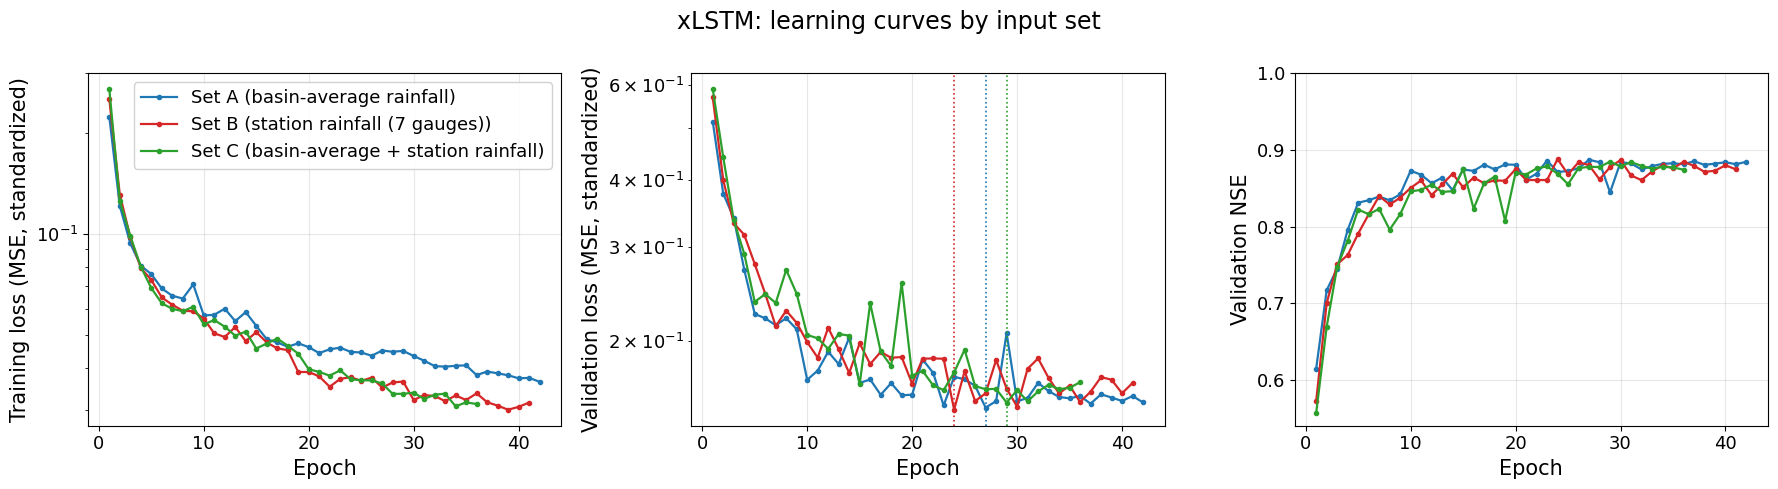

In [5]:
fig = common.plot_learning_curves(histories, title=f"{NAME}: learning curves by input set",
                                  labels={s: f"Set {s} ({common.INPUT_SET_NAMES[s]})" for s in SETS},
                                  colors=SET_COLOR, styles={s: "-" for s in SETS},
                                  best_epochs={s: summaries[s]["best_epoch"] for s in SETS})
common.save_fig(fig, f"{MODEL}_learning_curves")
plt.show()

## 4. 학습 / 검증 / 테스트 기간 성능

모든 지표는 **시간 단위, m³/s** 로 계산합니다 (MC-LSTM 의 mm/h 예측도 변환). 지표의 의미:

| 지표 | 의미 | 이상값 |
|---|---|---|
| NSE | 관측 평균 대비 설명력. 제곱오차 기반이라 **홍수(고유량)** 에 민감 | 1 |
| KGE | 상관(r)·변동성비(α)·편향비(β)를 함께 보는 지표 | 1 |
| RMSE / MAE | 오차의 크기 (m³/s) | 0 |
| PBIAS | 총량 편향(%) (+ 과대, − 과소) | 0 |
| Alpha-NSE / Beta-NSE | 표준편차 비 / 평균 편향(관측 표준편차로 정규화) | 1 / 0 |
| FHV / FMS / FLV | 유량지속곡선의 고유량(상위 2%) / 중간 구간 기울기 / 저유량(하위 30%) 편향(%) | 0 |
| Peak-Timing | 관측 첨두(자동 탐지)의 시각 오차 평균(h) | 0 |
| Peak-MAPE | 자동 탐지된 모든 첨두의 평균 절대 백분율 오차(%) | 0 |
| Missed-Peaks | 자동 탐지 첨두 중 예측이 놓친 비율 | 0 |

(첨두 자동 탐지는 라이브러리 기본 규칙으로 작은 첨두까지 포함하므로 값이 큽니다. 큰 홍수사건에 대한 분석은 6절과 `" + NB_PEAKS + "` 참고.)

In [6]:
rows = []
for s in SETS:
    for p in PERIODS:
        rows.append({"set": s, "period": p, **summaries[s]["metrics"][p]})
metrics_long = pd.DataFrame(rows).set_index(["set", "period"])[common.MAIN_METRICS]
display(metrics_long.round(3))
metrics_long.to_csv(common.RESULTS_DIR / f"{MODEL}_metrics_by_period.csv")

NSE    KGE    RMSE     MAE   PBIAS  Pearson-r  Alpha-NSE  Beta-NSE    FHV     FMS      FLV  Peak-Timing  Peak-MAPE  Missed-Peaks
set period                                                                                                                                        
A   train       0.926  0.956  19.493  10.741   2.335      0.964      1.008     0.009  0.198 -26.821   97.010        4.842     59.863         0.693
    validation  0.887  0.881  39.333  12.766  -3.665      0.943      0.902    -0.011 -3.678 -14.893   98.181        3.146     49.411         0.732
    test        0.894  0.892  28.196  11.974   9.477      0.948      1.001     0.031  0.449 -50.028   96.332        2.250     41.093         0.725
B   train       0.944  0.933  17.114  10.244   6.105      0.972      0.995     0.022 -1.150 -44.067 -133.914        4.321     57.464         0.621
    validation  0.888  0.844  39.158  12.782  -1.992      0.947      0.855    -0.006 -7.195 -32.678  -70.997        2.829     49.425         0.662
    test        0.939  0.865  21.465  11.617  12.699      0.970      0.965     0.041 -2.389 -59.452 -187.148        1.788     36.561         0.660
C   train       0.949  0.959  16.346   9.864   1.840      0.974      0.975     0.007 -3.699 -45.338 -133.185        4.052     58.553         0.631
    validation  0.885  0.847  39.758  12.617  -3.570      0.944      0.863    -0.010 -6.731 -34.058  -70.614        2.439     48.430         0.670
    test        0.932  0.891  22.644  11.669  10.043      0.966      0.975     0.032 -1.071 -62.170 -186.461        2.115     38.536         0.672

### 4.1 기간별 NSE · KGE · PBIAS 비교

학습 기간 대비 검증·테스트 기간의 하락 폭이 **일반화 성능**을 보여 줍니다. 입력세트 간 차이는 관측소별 강우(B, C)가 유역평균(A)보다
추가 정보를 주는지를 말해 줍니다.

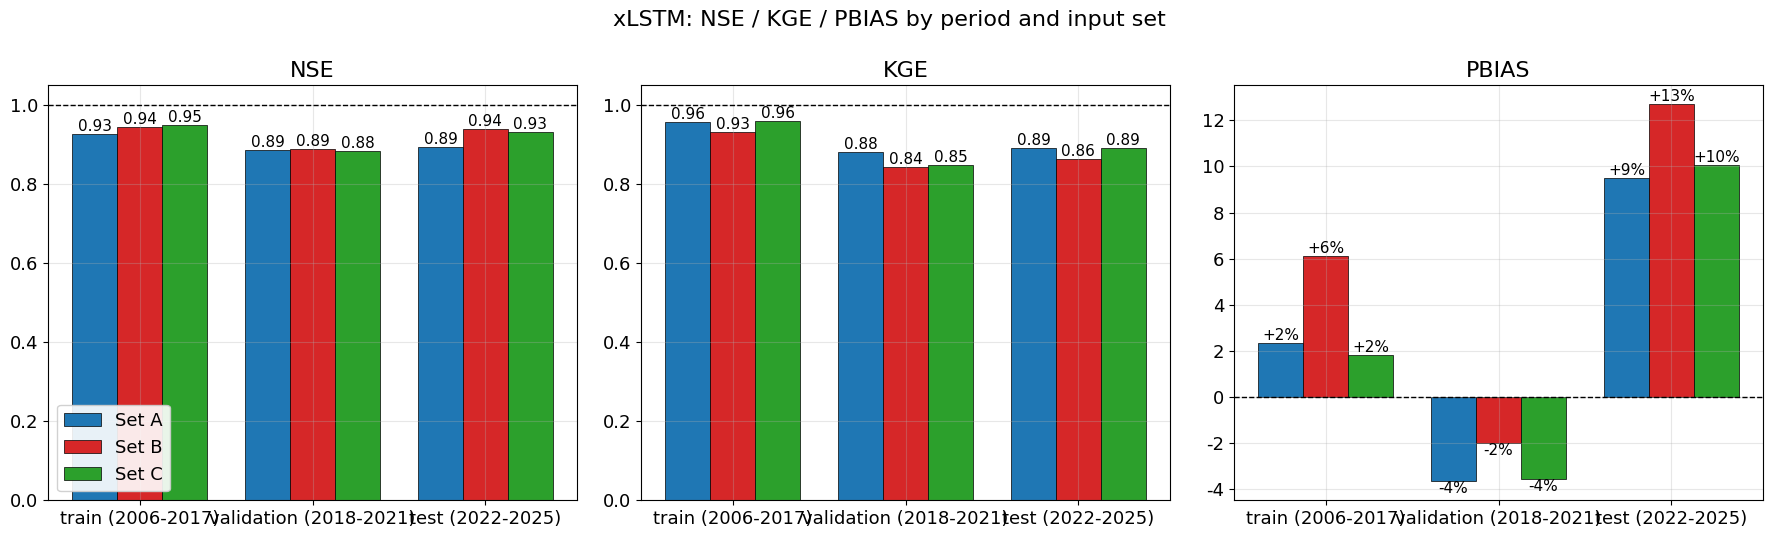

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, metric in zip(axes, ["NSE", "KGE", "PBIAS"]):
    x = np.arange(len(PERIODS))
    w = 0.26
    for i, s in enumerate(SETS):
        vals = [summaries[s]["metrics"][p][metric] for p in PERIODS]
        bars = ax.bar(x + (i - 1) * w, vals, w, label=f"Set {s}", color=SET_COLOR[s], edgecolor="black", lw=0.5)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{v:.2f}" if metric != "PBIAS" else f"{v:+.0f}%",
                    ha="center", va="bottom" if v >= 0 else "top", fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels([PERIOD_LABEL[p] for p in PERIODS])
    ax.set_title(metric)
    ax.axhline(common.METRIC_IDEAL[metric], color="black", ls="--", lw=1)
    if metric in ("NSE", "KGE"):
        ax.set_ylim(max(-0.5, min(0, ax.get_ylim()[0])), 1.05)
axes[0].legend(loc="lower left")
fig.suptitle(f"{NAME}: NSE / KGE / PBIAS by period and input set", fontsize=16)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_metrics_by_period")
plt.show()

### 4.2 관측 vs 예측 산점도 (로그축)

행 = 기간, 열 = 입력세트. 로그축이므로 저유량(수 m³/s)과 홍수(수천 m³/s)의 거동을 한 그림에서 볼 수 있습니다.
1:1 선 아래로 휘면 고유량 과소, 왼쪽 위로 퍼지면 저유량 과대입니다. 관측값 0 (전체의 약 16%) 은 0.1 로 잘라 표시합니다.

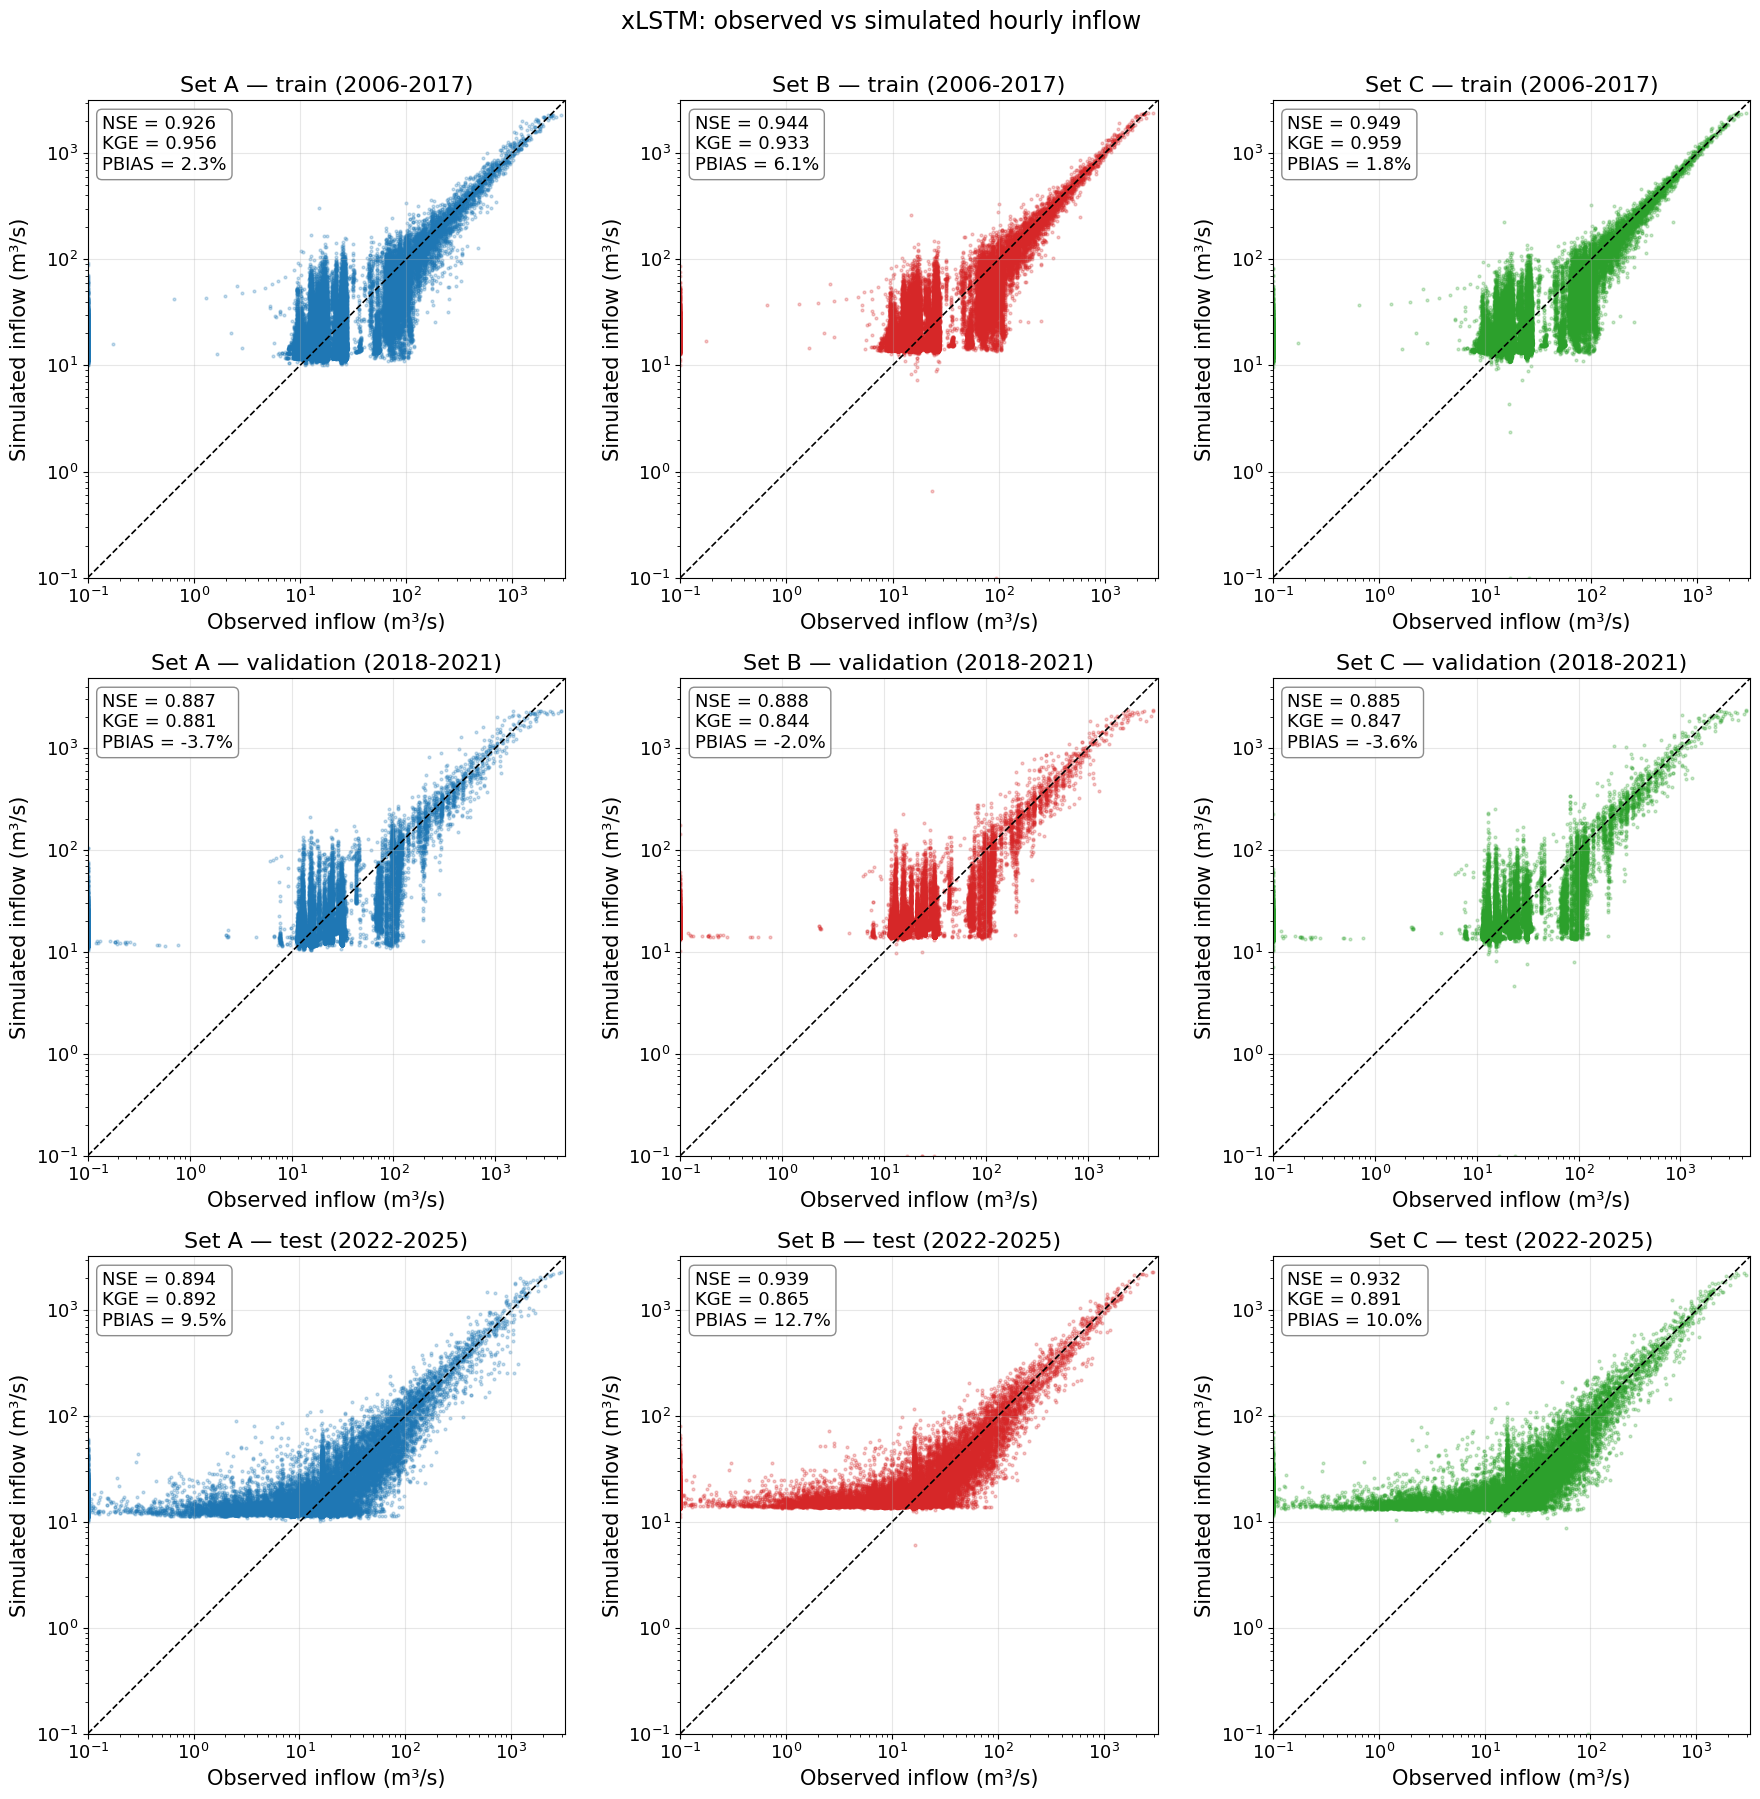

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(18, 18))
for i, p in enumerate(PERIODS):
    for j, s in enumerate(SETS):
        df = preds[s][preds[s]["period"] == p]
        common.plot_scatter(df["obs"], df["sim"], title=f"Set {s} — {PERIOD_LABEL[p]}", ax=axes[i, j], color=SET_COLOR[s])
fig.suptitle(f"{NAME}: observed vs simulated hourly inflow", fontsize=17, y=1.0)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_scatter")
plt.show()

## 5. 수문곡선 · 유량지속곡선

### 5.1 테스트 기간(2022–2025) 연도별 수문곡선

각 패널은 한 해의 시간 유입량입니다. 검은 선 = 관측, 색 선 = 입력세트별 예측, 위쪽 막대 = 유역평균 강우(역축).
홍수기(6–9월)의 첨두 크기와 상승·하강 시점, 건기의 저유량 수준을 봅니다.

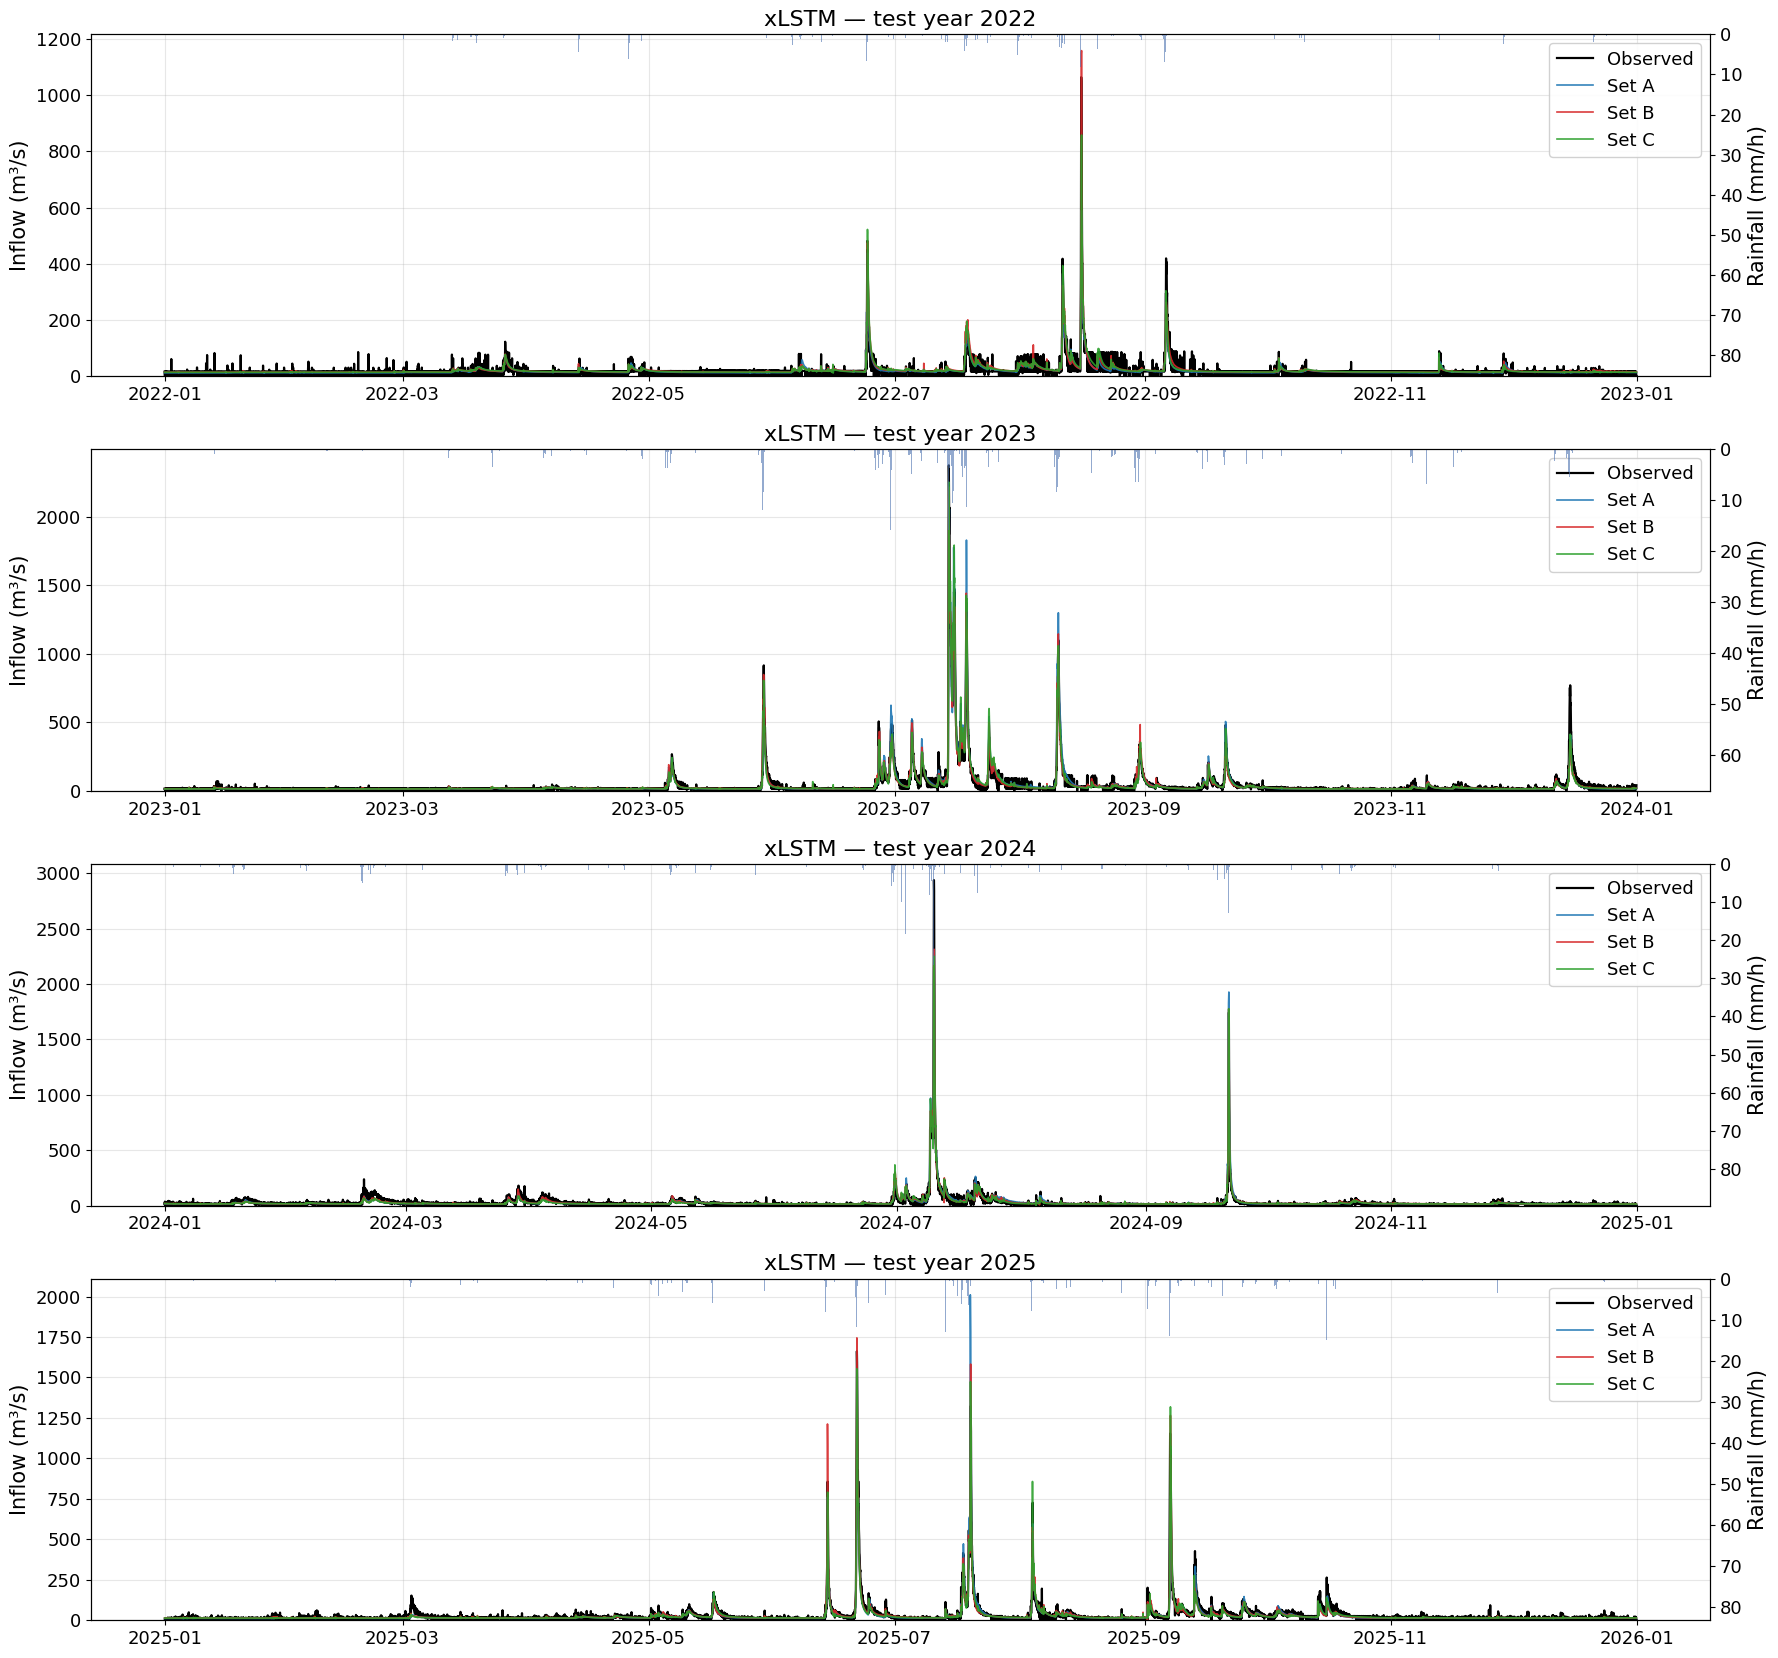

In [9]:
test_years = range(2022, 2026)
fig, axes = plt.subplots(len(test_years), 1, figsize=(18, 4.2 * len(test_years)))
for ax, year in zip(axes, test_years):
    start, end = f"{year}-01-01", f"{year}-12-31 23:00"
    obs = preds["A"].loc[start:end, "obs"]
    common.plot_hydrograph(obs, {f"Set {s}": preds[s].loc[start:end, "sim"] for s in SETS}, rain=rain.loc[start:end],
                           title=f"{NAME} — test year {year}", ax=ax, colors={f"Set {s}": SET_COLOR[s] for s in SETS},
                           styles={f"Set {s}": "-" for s in SETS}, sim_lw=1.2, obs_lw=1.6)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_hydrograph_test")
plt.show()

### 5.2 테스트 기간 최대 홍수사건 3개 확대

관측 첨두가 가장 큰 세 사건을 전후 5일 범위로 확대합니다. 시간 해상도이므로 첨두 **시각**까지 비교할 수 있습니다.

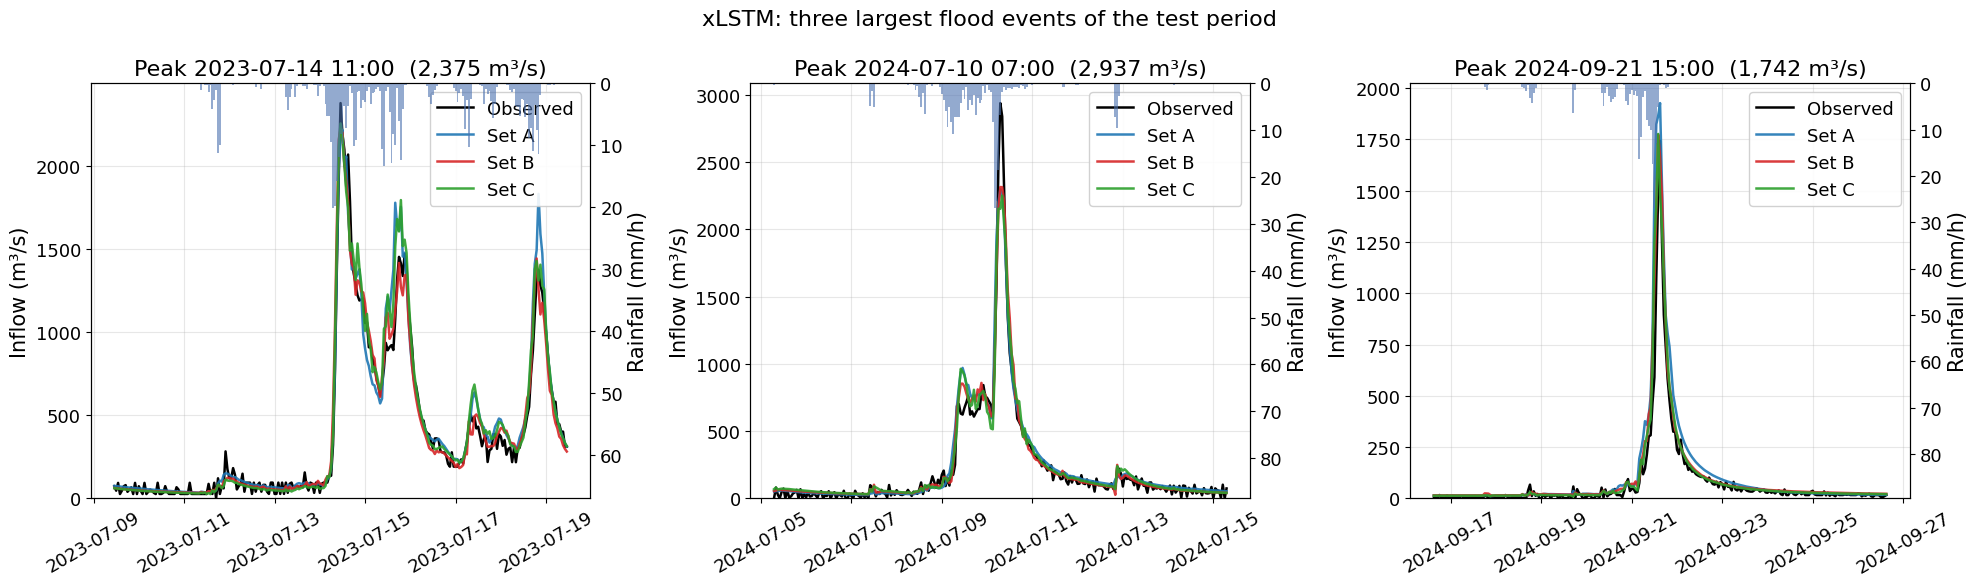

In [10]:
test_obs = preds["A"].loc[preds["A"]["period"] == "test", "obs"]
events = common.detect_events(test_obs, n_events=15)
top3 = sorted(events, key=lambda t: test_obs[t], reverse=True)[:3]
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, peak in zip(axes, sorted(top3)):
    start, end = peak - pd.Timedelta(days=5), peak + pd.Timedelta(days=5)
    common.plot_hydrograph(preds["A"]["obs"], {f"Set {s}": preds[s]["sim"] for s in SETS}, rain=rain, start=start, end=end,
                           title=f"Peak {peak:%Y-%m-%d %H:00}  ({test_obs[peak]:,.0f} m³/s)", ax=ax,
                           colors={f"Set {s}": SET_COLOR[s] for s in SETS}, styles={f"Set {s}": "-" for s in SETS}, sim_lw=1.8)
    ax.tick_params(axis="x", rotation=30)
fig.suptitle(f"{NAME}: three largest flood events of the test period", fontsize=16)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_events_top3")
plt.show()

### 5.3 유량지속곡선 (테스트 기간)

고유량(FHV, 왼쪽 음영)과 저유량(FLV, 오른쪽 음영) 구간에서 관측 곡선과의 간격이 각각 FHV, FLV 지표에 해당합니다.

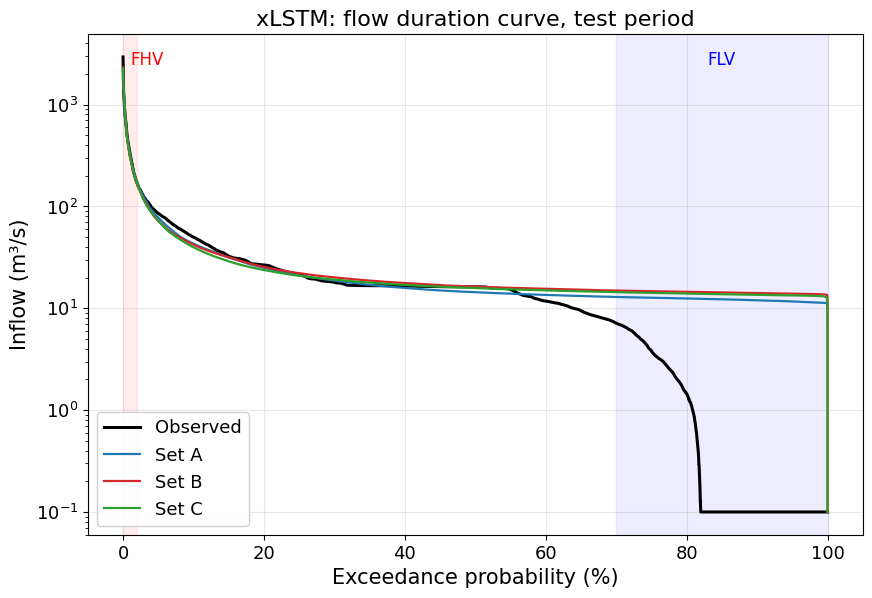

In [11]:
fig, ax = plt.subplots(figsize=(10, 6.5))
common.plot_fdc(test_obs, {f"Set {s}": preds[s].loc[preds[s]["period"] == "test", "sim"] for s in SETS},
                title=f"{NAME}: flow duration curve, test period", colors={f"Set {s}": SET_COLOR[s] for s in SETS}, ax=ax)
common.save_fig(fig, f"{MODEL}_fdc_test")
plt.show()

### 5.4 연도별 NSE

20년 전체를 연도별로 나눠 본 NSE 입니다. 배경 음영은 학습/검증/테스트 기간. 특정 해의 성능 급락은 보통 그 해의 큰 홍수를 놓쳤음을 뜻합니다.

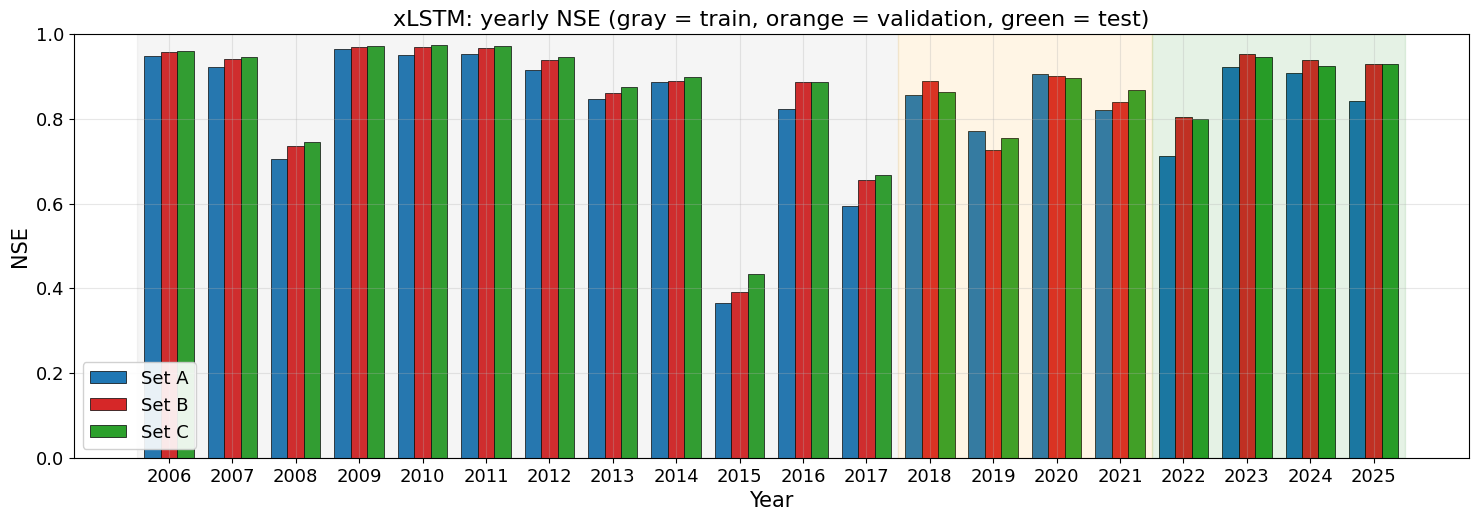

A             B             C       
        NSE    KGE    NSE    KGE    NSE    KGE
year                                          
2006  0.948  0.901  0.957  0.908  0.960  0.941
2007  0.922  0.946  0.941  0.962  0.947  0.962
2008  0.706  0.765  0.735  0.755  0.746  0.753
2009  0.964  0.771  0.970  0.743  0.973  0.792
2010  0.951  0.967  0.970  0.966  0.975  0.979
2011  0.953  0.959  0.968  0.980  0.972  0.960
2012  0.915  0.906  0.939  0.928  0.945  0.904
2013  0.848  0.829  0.861  0.904  0.875  0.861
2014  0.886  0.922  0.889  0.912  0.898  0.925
2015  0.366  0.563  0.390  0.521  0.434  0.510
2016  0.823  0.867  0.887  0.836  0.887  0.842
2017  0.595  0.716  0.655  0.658  0.669  0.654
2018  0.856  0.869  0.890  0.848  0.863  0.836
2019  0.772  0.746  0.726  0.726  0.755  0.764
2020  0.906  0.778  0.901  0.771  0.897  0.756
2021  0.821  0.796  0.840  0.824  0.868  0.846
2022  0.712  0.634  0.805  0.724  0.800  0.724
2023  0.922  0.895  0.953  0.920  0.945  0.928
2024  0.908  0.803  0.939  0.803  0.926  0.855
2025  0.842  0.883  0.930  0.904  0.930  0.906

In [12]:
yearly = {s: common.yearly_metrics(preds[s]) for s in SETS}
fig, ax = plt.subplots(figsize=(18, 5.5))
years = yearly["A"].index
w = 0.26
for i, s in enumerate(SETS):
    ax.bar(years + (i - 1) * w, yearly[s]["NSE"], w, label=f"Set {s}", color=SET_COLOR[s], edgecolor="black", lw=0.5)
ax.axvspan(2005.5, 2017.5, color="gray", alpha=0.08)
ax.axvspan(2017.5, 2021.5, color="orange", alpha=0.10)
ax.axvspan(2021.5, 2025.5, color="green", alpha=0.10)
ax.set_ylim(max(-1, min(0, np.nanmin([yearly[s]["NSE"].min() for s in SETS]) - 0.05)), 1.0)
ax.set_xticks(years)
ax.set_ylabel("NSE")
ax.set_xlabel("Year")
ax.set_title(f"{NAME}: yearly NSE (gray = train, orange = validation, green = test)")
ax.legend(loc="lower left")
common.save_fig(fig, f"{MODEL}_yearly_nse")
plt.show()
display(pd.concat({s: yearly[s][["NSE", "KGE"]] for s in SETS}, axis=1).round(3))

## 6. 홍수 첨두 재현 (테스트 기간 상위 15개 사건)

관측 첨두를 서로 72시간 이상 떨어지도록 골라 독립 사건 15개를 정의하고, 사건마다

- **첨두 크기 오차** = (예측 첨두 − 관측 첨두) / 관측 첨두 × 100 (%) — 예측 첨두는 관측 첨두 ±24 h 안의 최대값
- **첨두 시각 오차** = 예측 첨두 시각 − 관측 첨두 시각 (h, + 는 지연)
- **사건 체적 오차** = 첨두 전 48 h ~ 후 96 h 구간 총량의 상대오차 (%)
- **사건 NSE** = 같은 구간의 NSE

를 계산합니다. 댐 운영에서는 평균적 적합도(NSE)보다 이 값들이 직접적인 관심사입니다.

In [13]:
event_tables = {s: common.load_saved_events(MODEL, s) for s in SETS}
best_set = max(SETS, key=lambda s: summaries[s]["metrics"]["test"]["NSE"])
print(f"테스트 NSE 가 가장 높은 입력세트: {best_set}")
t = event_tables[best_set].copy()
t[t.select_dtypes("number").columns] = t.select_dtypes("number").round(1)
display(t)
display(pd.DataFrame({s: summaries[s]["events_test"] for s in SETS}).round(2))

테스트 NSE 가 가장 높은 입력세트: B


,obs_peak,sim_peak,sim_peak_time,peak_error_pct,timing_error_h,volume_error_pct,event_NSE
obs_peak_time,,,,,,,
2022-08-16 07:00:00,1064.7,1159.5,2022-08-16 09:00:00,8.9,2.0,-1.1,0.9
2023-05-29 14:00:00,915.1,847.9,2023-05-29 13:00:00,-7.3,-1.0,-12.7,1.0
2023-06-27 02:00:00,506.0,432.8,2023-06-27 06:00:00,-14.5,4.0,-1.4,0.8
2023-07-05 08:00:00,515.2,495.1,2023-07-05 07:00:00,-3.9,-1.0,11.1,0.9
2023-07-14 11:00:00,2375.1,2217.0,2023-07-14 11:00:00,-6.7,0.0,1.1,1.0
2023-07-18 20:00:00,1372.7,1441.8,2023-07-18 19:00:00,5.0,-1.0,3.1,1.0
2023-08-10 16:00:00,1097.7,1145.0,2023-08-10 15:00:00,4.3,-1.0,-5.3,0.9
2023-12-15 13:00:00,769.9,355.3,2023-12-15 13:00:00,-53.8,0.0,-43.8,0.6
2024-07-10 07:00:00,2936.9,2313.2,2024-07-10 07:00:00,-21.2,0.0,1.1,1.0


,A,B,C
n_events,15.00,15.00,15.00
peak_error_mean_pct,-12.54,-2.17,-7.91
peak_error_median_pct,-17.86,1.74,-6.55
peak_abs_error_mean_pct,27.99,14.93,14.50
timing_error_mean_h,0.47,0.00,0.07
timing_abs_error_mean_h,1.13,1.07,1.00
timing_within_3h_frac,1.00,0.93,1.00
peak_within_20pct_frac,0.40,0.73,0.80
volume_error_mean_pct,-0.25,-0.83,-3.10
event_NSE_median,0.82,0.93,0.91


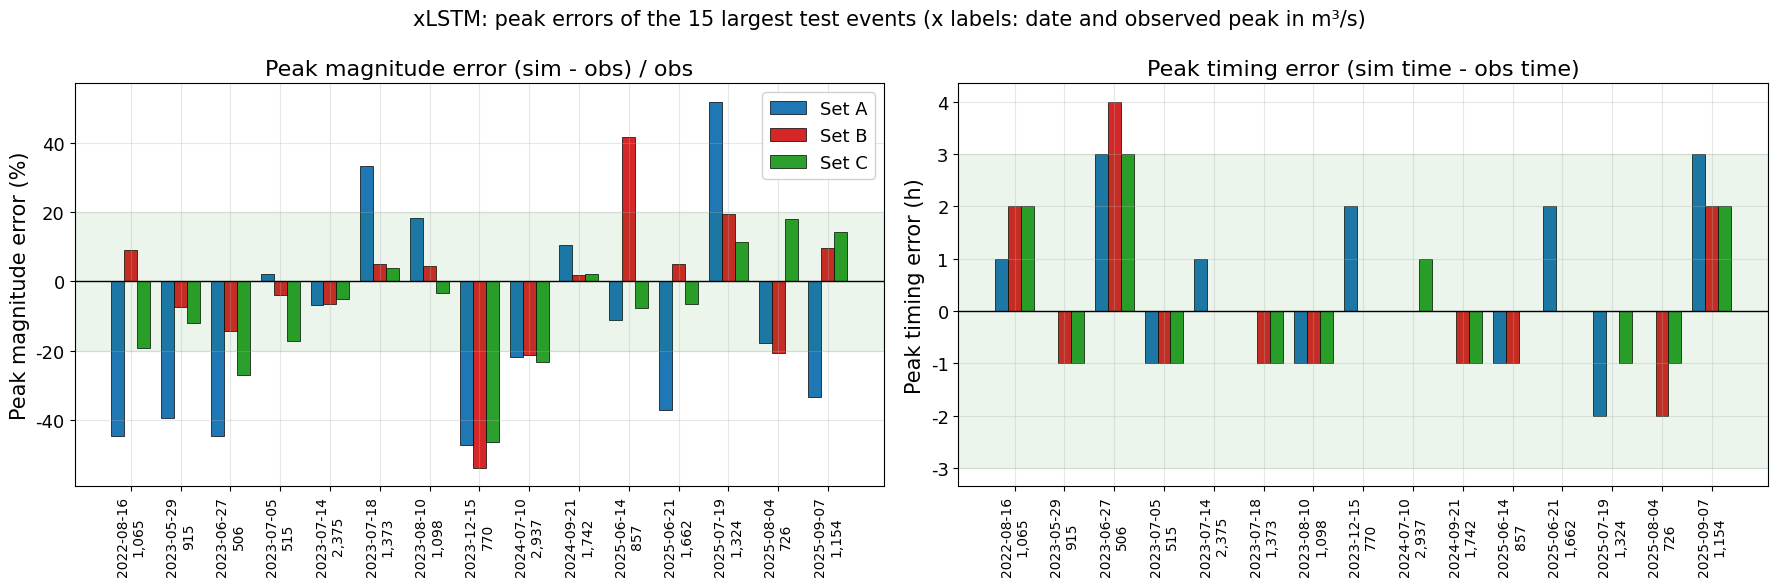

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
table = event_tables["A"]
x = np.arange(len(table))
w = 0.26
for i, s in enumerate(SETS):
    t = event_tables[s].reindex(table.index)
    axes[0].bar(x + (i - 1) * w, t["peak_error_pct"], w, label=f"Set {s}", color=SET_COLOR[s], edgecolor="black", lw=0.5)
    axes[1].bar(x + (i - 1) * w, t["timing_error_h"], w, label=f"Set {s}", color=SET_COLOR[s], edgecolor="black", lw=0.5)
labels = [f"{t:%Y-%m-%d}\n{v:,.0f}" for t, v in zip(table.index, table["obs_peak"])]
for ax, ylabel, title in zip(axes, ["Peak magnitude error (%)", "Peak timing error (h)"],
                             ["Peak magnitude error (sim - obs) / obs", "Peak timing error (sim time - obs time)"]):
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=90, fontsize=10)
    ax.axhline(0, color="black", lw=1)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
axes[0].axhspan(-20, 20, color="green", alpha=0.08)
axes[1].axhspan(-3, 3, color="green", alpha=0.08)
axes[0].legend(loc="best")
fig.suptitle(f"{NAME}: peak errors of the 15 largest test events (x labels: date and observed peak in m³/s)", fontsize=15)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_peak_errors")
plt.show()

## 7. 결과 해석

### 7.1 자동 요약 (지표 기반)

아래 글은 `common.narrative_for_run()` 이 지표 값으로부터 규칙적으로 생성한 요약입니다. 모든 모델 노트북에 같은 규칙을 적용하므로
모델 간 서술이 일관됩니다.

In [15]:
for s in SETS:
    display(Markdown(common.narrative_for_run(summaries[s])))

**xLSTM / 입력세트 A (basin-average rainfall)**
- 테스트 기간 NSE 0.894, KGE 0.892, RMSE 28.2 m³/s, PBIAS +9.5%.
- 학습 NSE 0.926, 검증 NSE 0.887: 테스트 기간에서 성능이 다소 낮아지지만 큰 과적합 징후는 없습니다.
- 고유량 구간(FHV +0.4%)은 거의 편향 없이 재현되고, 저유량 구간(FLV +96.3%)은 크게 과대 재현됩니다.
- 테스트 기간 상위 15개 홍수사건: 첨두 크기 오차 중앙값 -17.9%, 평균 절대 첨두오차 28.0%, 첨두 시각 오차 평균 +0.5 h (±3 h 이내 100%, 크기 ±20% 이내 40%).
- 학습: 42 epoch (early stopping), 최적 epoch 27, epoch당 평균 158 s, 총 학습시간 110.4 min, 파라미터 63,945개.

**xLSTM / 입력세트 B (station rainfall (7 gauges))**
- 테스트 기간 NSE 0.939, KGE 0.865, RMSE 21.5 m³/s, PBIAS +12.7%.
- 학습(0.944)·검증(0.888)·테스트 NSE가 비슷해 **일반화가 안정적**입니다.
- 전체 유량을 과대 추정하는 경향(PBIAS +12.7%)이 뚜렷합니다.
- 고유량 구간(FHV -2.4%)은 거의 편향 없이 재현되고, 저유량 구간(FLV -187.1%)은 과소 재현됩니다.
- 테스트 기간 상위 15개 홍수사건: 첨두 크기 오차 중앙값 +1.7%, 평균 절대 첨두오차 14.9%, 첨두 시각 오차 평균 +0.0 h (±3 h 이내 93%, 크기 ±20% 이내 73%).
- 학습: 41 epoch (early stopping), 최적 epoch 24, epoch당 평균 155 s, 총 학습시간 106.0 min, 파라미터 64,329개.

**xLSTM / 입력세트 C (basin-average + station rainfall)**
- 테스트 기간 NSE 0.932, KGE 0.891, RMSE 22.6 m³/s, PBIAS +10.0%.
- 학습(0.949)·검증(0.885)·테스트 NSE가 비슷해 **일반화가 안정적**입니다.
- 전체 유량을 과대 추정하는 경향(PBIAS +10.0%)이 뚜렷합니다.
- 고유량 구간(FHV -1.1%)은 거의 편향 없이 재현되고, 저유량 구간(FLV -186.5%)은 과소 재현됩니다.
- 테스트 기간 상위 15개 홍수사건: 첨두 크기 오차 중앙값 -6.6%, 평균 절대 첨두오차 14.5%, 첨두 시각 오차 평균 +0.1 h (±3 h 이내 100%, 크기 ±20% 이내 80%).
- 학습: 36 epoch (early stopping), 최적 epoch 29, epoch당 평균 156 s, 총 학습시간 93.3 min, 파라미터 64,393개.

### 7.2 xLSTM 의 결과 해석

**요약**: 테스트 NSE 0.89 (A), **0.939 (B, 전체 30개 run 중 최고)**, 0.932 (C). 첨두 재현도 가장 좋다(세트 B·C 첨두 크기 평균 절대 오차
15%, ±20% 이내 73–80%, 시각 오차 1.0–1.1 h).

- **입력세트 효과**: LSTM·GRU 와 반대로 **관측소별 강우가 도움이 된다**(A 0.894 → B 0.939). 행렬 메모리(mLSTM)와 다중 헤드가 7개 관측소의
  공간 분포를 서로 다른 키로 저장할 수 있다는 설계 의도와 부합하는 결과다. 학습 NSE(0.93–0.95)와 테스트 NSE 의 차이가 0.01–0.03 으로 작아
  과적합 없이 추가 입력을 활용했다.
- **총량**: PBIAS +9 ~ +13% 로 과대 추정이 있고, 저유량 바닥값이 LSTM 보다 높다. KGE(0.86–0.89)가 NSE 에 비해 낮은 이유다.
- **홍수 첨두**: 세트 B 는 첨두 크기 오차 중앙값 +1.7%, 세트 C 는 −6.6% 로 거의 편향이 없고, 최대 사건(2024-07-10) 도 ±10% 안에서 맞췄다.
  첨두 시각은 93–100% 가 ±3 h 이내다. 지수 게이트가 집중호우에 포화되지 않는다는 설계 특성이 첨두 크기 재현에 유리하게 작용한 것으로 해석된다.
- **비용**: 155–158 s/epoch 로 LSTM 의 **약 19배**, GPU 메모리 약 21 GB (720 단계 mLSTM 병렬 커널). run 당 1.7–2 시간이 걸렸고 다른 run 과
  GPU 를 공유할 수 없었다. 정확도 대비 비용이 가장 큰 모델이다.


## 8. 요약

아래 표가 이 노트북의 최종 결과이며, `results/xlstm_<set>/summary.json` 으로 저장되어 비교 노트북에서 사용됩니다.

In [16]:
summary_table = pd.DataFrame({
    f"Set {s}": {
        "parameters": summaries[s]["n_parameters"],
        "epochs trained": summaries[s]["epochs_trained"],
        "best epoch": summaries[s]["best_epoch"],
        "early stopped": summaries[s]["early_stopped"],
        "s / epoch": round(summaries[s]["epoch_time_mean_s"], 1),
        "training time (min)": round(summaries[s]["train_time_total_s"] / 60, 1),
        "test NSE": round(summaries[s]["metrics"]["test"]["NSE"], 3),
        "test KGE": round(summaries[s]["metrics"]["test"]["KGE"], 3),
        "test RMSE (m³/s)": round(summaries[s]["metrics"]["test"]["RMSE"], 1),
        "test PBIAS (%)": round(summaries[s]["metrics"]["test"]["PBIAS"], 1),
        "test FHV (%)": round(summaries[s]["metrics"]["test"]["FHV"], 1),
        "peak |error| mean (%)": round(summaries[s]["events_test"]["peak_abs_error_mean_pct"], 1),
        "peak |timing| mean (h)": round(summaries[s]["events_test"]["timing_abs_error_mean_h"], 1),
    } for s in SETS})
display(summary_table)
summary_table.to_csv(common.RESULTS_DIR / f"{MODEL}_summary_table.csv")

,Set A,Set B,Set C
parameters,63945,64329,64393
epochs trained,42,41,36
best epoch,27,24,29
early stopped,True,True,True
s / epoch,157.6,155.1,155.5
training time (min),110.4,106.0,93.3
test NSE,0.894,0.939,0.932
test KGE,0.892,0.865,0.891
test RMSE (m³/s),28.2,21.5,22.6
test PBIAS (%),9.5,12.7,10.0
